<a href="https://colab.research.google.com/github/alla-malts-ds/data-visualization-practice/blob/main/%22HW_11_3_%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D1%87%D0%BD%D1%96_%D0%B2%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%97_%D0%B7_Seaborn_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Data_Loves_Academy/Module 11/yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour


---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

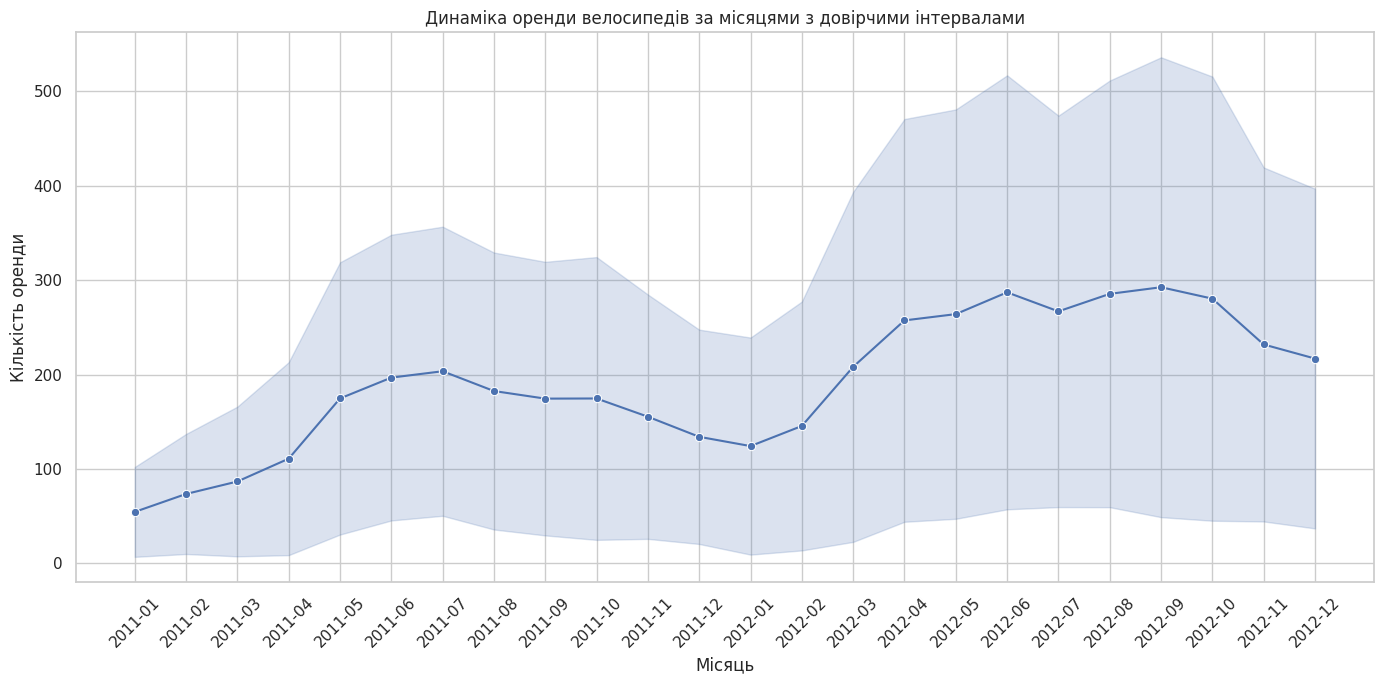

In [3]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df,
    x='month_year',
    y='count',
    errorbar='sd',
    marker='o',
    color='#4C72B0'
)

plt.title(
    'Динаміка оренди велосипедів за місяцями з довірчими інтервалами'
)
plt.xlabel('Місяць')
plt.ylabel('Кількість оренди')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Найбільша невизначеність у даних спостерігається у другій половині 2012 року, особливо приблизно з серпня по жовтень. Це видно за ширшою зафарбованою областю навколо лінії середнього. Широка область означає більше стандартне відхилення, тобто погодинна кількість оренд у цих місяцях сильніше відрізнялася від середнього значення. Імовірно, це пов’язано з великою різницею між годинами низького попиту та піковими годинами.

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

In [4]:
df['temp'].describe()

,temp
count,10886.00000
mean,20.23086
std,7.79159
min,0.82000
25%,13.94000
50%,20.50000
75%,26.24000
max,41.00000


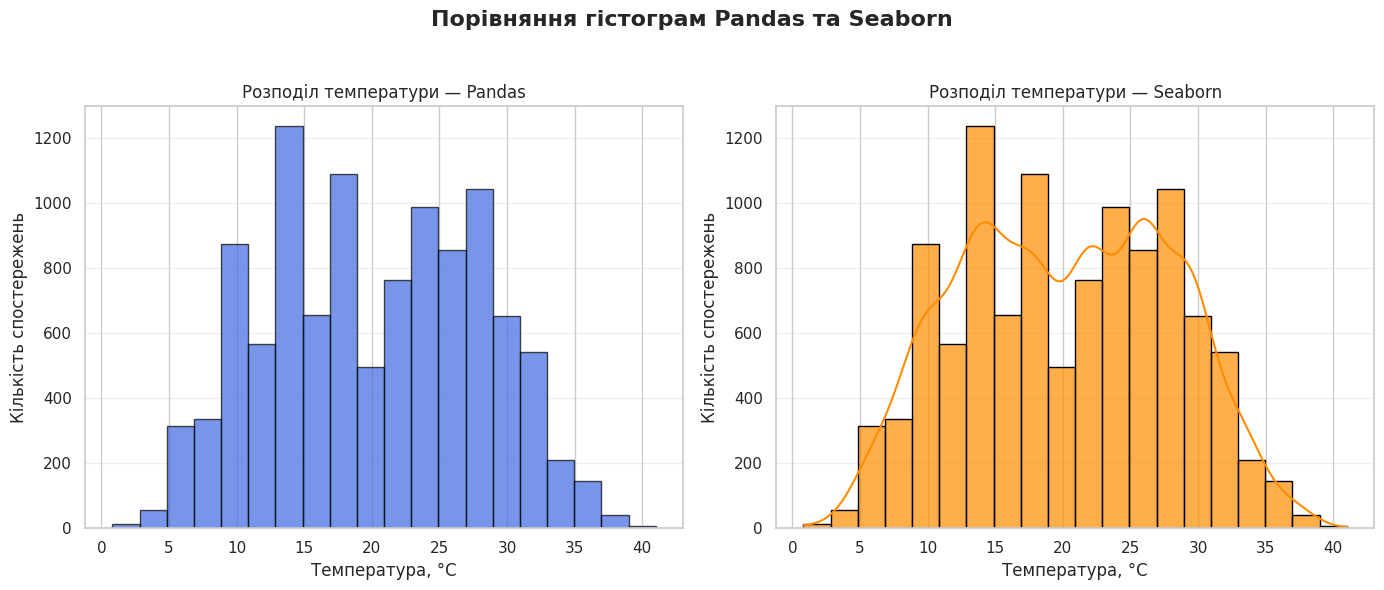

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df['temp'].plot(
    kind='hist',
    bins=20,
    color='royalblue',
    edgecolor='black',
    alpha=0.7,
    ax=axes[0]
)

axes[0].set_title('Розподіл температури — Pandas')
axes[0].set_xlabel('Температура, °C')
axes[0].set_ylabel('Кількість спостережень')
axes[0].grid(axis='y', alpha=0.3)

sns.histplot(
    data=df,
    x='temp',
    bins=20,
    kde=True,
    color='darkorange',
    edgecolor='black',
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title('Розподіл температури — Seaborn')
axes[1].set_xlabel('Температура, °C')
axes[1].set_ylabel('Кількість спостережень')
axes[1].grid(axis='y', alpha=0.3)

fig.suptitle(
    'Порівняння гістограм Pandas та Seaborn',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

1.Обидві гістограми показують той самий розподіл температури й використовують однакову кількість бінів, тому розташування та висота стовпчиків мають бути подібними. Pandas створює простішу базову гістограму, яку зручно використовувати для швидкого аналізу. Гістограма Seaborn має більш виразне статистичне оформлення та додаткову плавну KDE-лінію. Отже, основна візуальна різниця полягає не в даних, а в оформленні та наявності додаткового відображення форми розподілу в Seaborn.
2.Додаткова лінія називається KDE, або ядерною оцінкою щільності розподілу. Вона додається за допомогою параметра kde=True. Простими словами, KDE-лінія згладжує форму гістограми та показує, у яких температурних діапазонах спостереження концентруються найчастіше. Піки лінії відповідають діапазонам температури з більшою концентрацією значень, а нижчі ділянки показують температури, що зустрічалися рідше.


## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

In [6]:
weather_labels = {
    1: 'Ясно',
    2: 'Туман',
    3: 'Легкий дощ',
    4: 'Сильний дощ'
}
df['weather_label'] = df['weather'].map(weather_labels)
df[['weather', 'weather_label']].head()

,weather,weather_label
datetime,,
2011-01-01 00:00:00,1,Ясно
2011-01-01 01:00:00,1,Ясно
2011-01-01 02:00:00,1,Ясно
2011-01-01 03:00:00,1,Ясно
2011-01-01 04:00:00,1,Ясно


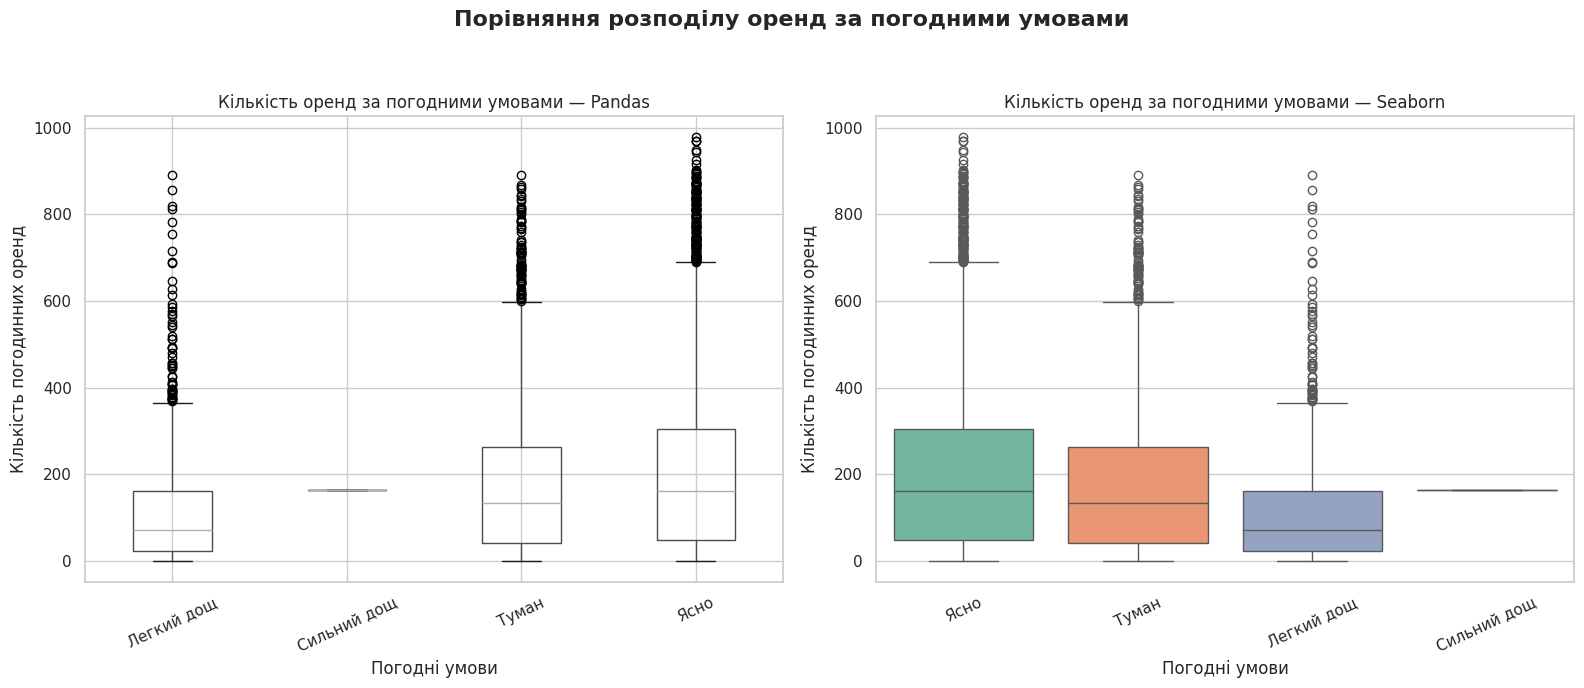

In [7]:
weather_order = [
    'Ясно',
    'Туман',
    'Легкий дощ',
    'Сильний дощ'
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

df.boxplot(
    column='count',
    by='weather_label',
    ax=axes[0],
    grid=True
)

axes[0].set_title('Кількість оренд за погодними умовами — Pandas')
axes[0].set_xlabel('Погодні умови')
axes[0].set_ylabel('Кількість погодинних оренд')
axes[0].tick_params(axis='x', rotation=25)

sns.boxplot(
    data=df,
    x='weather_label',
    y='count',
    order=weather_order,
    hue='weather_label',
    palette='Set2',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Кількість оренд за погодними умовами — Seaborn')
axes[1].set_xlabel('Погодні умови')
axes[1].set_ylabel('Кількість погодинних оренд')
axes[1].tick_params(axis='x', rotation=25)

fig.suptitle(
    'Порівняння розподілу оренд за погодними умовами',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Pandas і Seaborn box plot показують однакову статистичну інформацію, але відрізняються оформленням. Pandas створює простий базовий графік, тоді як Seaborn має більш сучасний вигляд і дозволяє легко використовувати різні кольори для категорій. Мені більше подобається Seaborn, оскільки кольорові ящики допомагають швидше розрізняти погодні умови.


<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


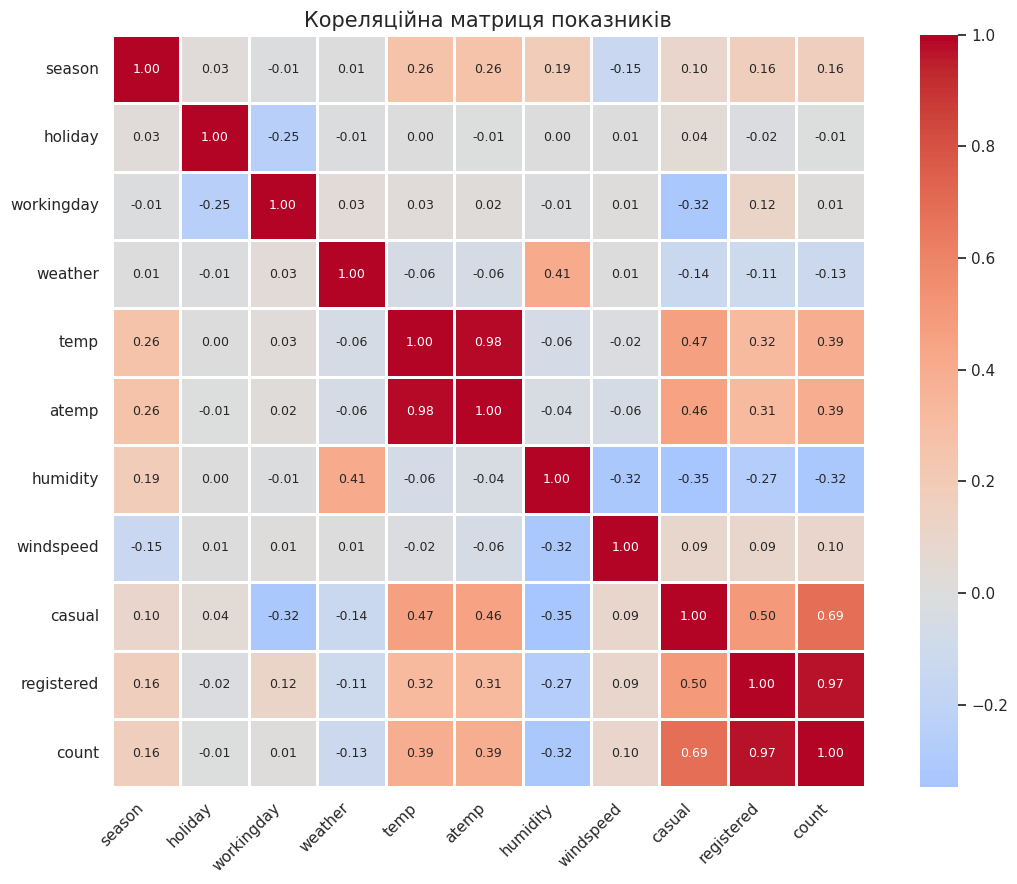

In [8]:
columns = [
    'season',
    'holiday',
    'workingday',
    'weather',
    'temp',
    'atemp',
    'humidity',
    'windspeed',
    'casual',
    'registered',
    'count'
]

correlation = df[columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=1,
    fmt='.2f',
    annot_kws={'size': 9}
)

plt.title('Кореляційна матриця показників', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

1. Найсильніше із загальною кількістю оренд count корелюють registered (0,97) та casual (0,69), оскільки count є сумою цих двох показників. Серед погодних змінних найсильнішу позитивну кореляцію мають temp і atemp, по 0,39.

2. Кореляція між temp та atemp становить 0,98. Це дуже сильна позитивна кореляція, оскільки обидві змінні характеризують температуру: temp показує фактичну температуру, а atemp показує температуру за відчуттям.

3. Негативну кореляцію з count мають humidity (−0,32), weather (−0,13) і holiday (−0,01). Найпомітніший негативний зв’язок має вологість: за її збільшення кількість оренд зазвичай зменшується.

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


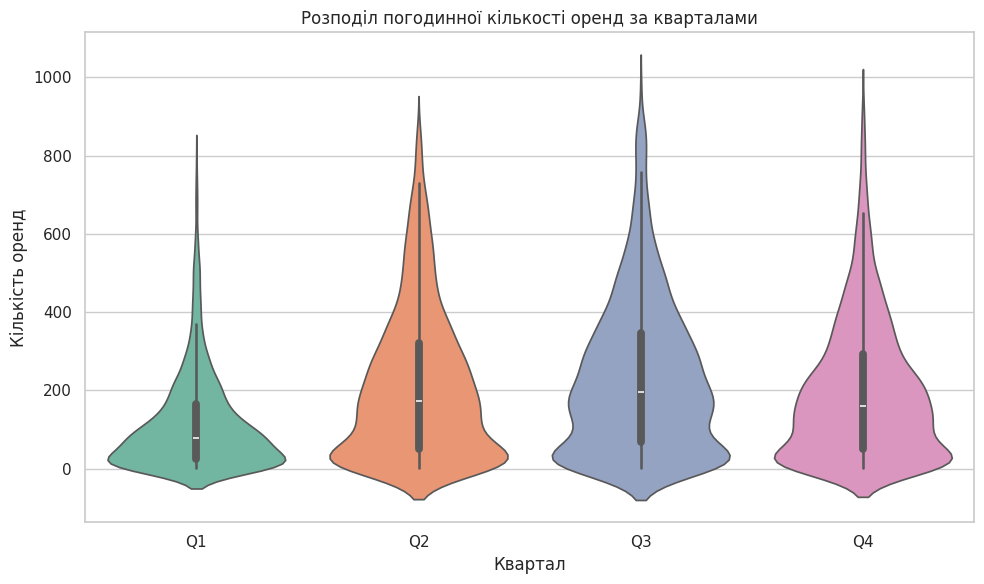

In [9]:
quarter_labels = {
    1: 'Q1',
    2: 'Q2',
    3: 'Q3',
    4: 'Q4'
}

df['quarter'] = df['season'].map(quarter_labels)

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='quarter',
    y='count',
    order=['Q1', 'Q2', 'Q3', 'Q4'],
    hue='quarter',
    palette='Set2',
    legend=False,
    inner='box'
)

plt.title('Розподіл погодинної кількості оренд за кварталами')
plt.xlabel('Квартал')
plt.ylabel('Кількість оренд')
plt.tight_layout()
plt.show()

1. Товщина violin plot показує щільність розподілу. Широка частина означає, що відповідні значення оренди трапляються часто, а вузька частина означає, що вони зустрічаються рідше.

2. Найбільша варіабельність оренди спостерігається в Q3, оскільки цей квартал має найбільший вертикальний діапазон і широкий внутрішній розподіл значень. Найменша варіабельність помітна в Q1.

3. Перевага violin plot над box plot полягає в тому, що violin plot показує не лише медіану та квартилі, а й повну форму та щільність розподілу. Це допомагає побачити концентрацію значень, асиметрію та можливі піки розподілу.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

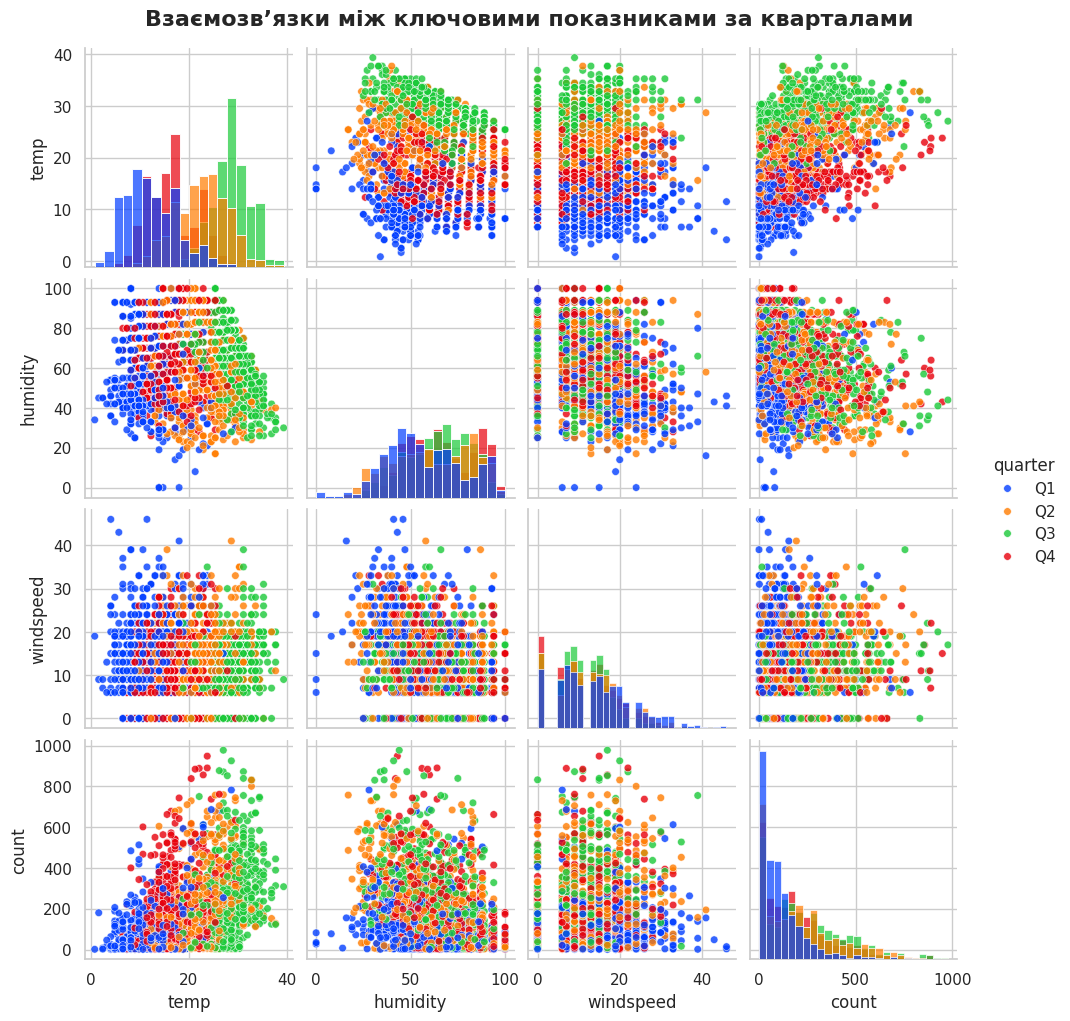

In [13]:
quarter_labels = {
    1: 'Q1',
    2: 'Q2',
    3: 'Q3',
    4: 'Q4'
}

df['quarter'] = df['season'].map(quarter_labels)

sample_df = df[
    ['temp', 'humidity', 'windspeed', 'count', 'quarter']
].sample(2000, random_state=42)

sns.pairplot(
    sample_df,
    vars=['temp', 'humidity', 'windspeed', 'count'],
    hue='quarter',
    hue_order=['Q1', 'Q2', 'Q3', 'Q4'],
    palette='bright',
    diag_kind='hist',
    plot_kws={
        'alpha': 0.8,
        's': 30
    },
    diag_kws={
        'alpha': 0.7,
        'edgecolor': 'white'
    }
)

plt.suptitle(
    'Взаємозв’язки між ключовими показниками за кварталами',
    y=1.02,
    fontsize=16,
    fontweight='bold'
)

plt.show()

#1. Між якими змінними спостерігається найсильніший лінійний зв’язок?

Найсильніший позитивний лінійний зв’язок спостерігається між температурою temp і кількістю оренд count. На графіку видно, що зі зростанням температури точки поступово зміщуються вгору, тобто кількість оренд загалом збільшується. За попередньою кореляційною матрицею коефіцієнт кореляції між temp і count становить 0,39, що відповідає помірному позитивному зв’язку.

Також помітний негативний зв’язок між вологістю humidity і кількістю оренд count: за високої вологості високі значення оренди зустрічаються рідше. Коефіцієнт кореляції становить приблизно −0,32.

Між швидкістю вітру windspeed і кількістю оренд count чіткого лінійного зв’язку майже не видно. Раніше розрахований коефіцієнт становив лише 0,10.

#2. 2. Яка характеристика найбільше відрізняється між кварталами?
Найбільше між кварталами відрізняється температура temp. Розподіли кольорових точок і гістограми на діагоналі показують чітке розділення кварталів за температурою:

Q1, сині точки, переважно відповідає нижчим температурам, приблизно від 5 до 20 °C;
Q2, помаранчеві точки, частіше розташований у середньому температурному діапазоні;
Q3, зелені точки, має найвищі температури, часто приблизно від 20 до 35 °C;
Q4, червоні точки, переважно займає проміжний діапазон.

Кількість оренд count також помітно відрізняється: у Q1 переважають нижчі значення, тоді як у Q3 та Q4 частіше зустрічаються високі значення приблизно від 400 до 900 оренд. Однак найчіткіше розмежування кольорів між кварталами спостерігається саме за температурою.

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

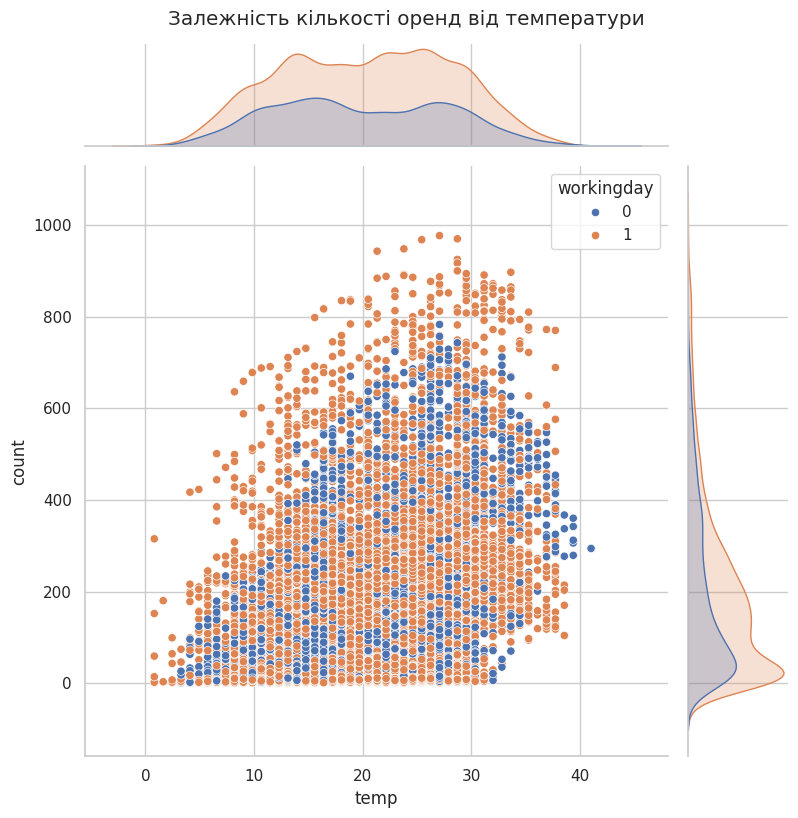

In [15]:
workingday_labels = {
    0: 'Неробочий день',
    1: 'Робочий день'
}

df['workingday_label'] = df['workingday'].map(workingday_labels)

sns.jointplot(
    data=df,
    x='temp',
    y='count',
    hue='workingday',
    kind='scatter',
    height=8
)

plt.suptitle(
    'Залежність кількості оренд від температури',
    y=1.02
)

plt.show()

#1. Що показують графіки по краях?
Графіки по краях показують розподіл кожної змінної окремо. Верхній графік відображає розподіл температури temp, а правий графік показує розподіл погодинної кількості оренд count.

Синім кольором позначені неробочі дні (workingday = 0), а помаранчевим кольором — робочі дні (workingday = 1). Верхній графік показує, за яких температур було найбільше спостережень, а правий допомагає порівняти, які значення кількості оренд частіше траплялися в робочі та неробочі дні.

Такі графіки називаються маргінальними розподілами. Вони доповнюють центральну діаграму розсіювання, де показаний спільний зв’язок між температурою та кількістю оренд.

#2.Чи є різниця в поведінці користувачів у робочий і неробочий день?
Так, певна різниця є. На центральному графіку помаранчеві точки, які відповідають робочим дням, частіше досягають високих значень кількості оренд. Максимальні значення в робочі дні наближаються до 900–1000 оренд, тоді як у неробочі дні високі значення переважно не перевищують приблизно 700–750 оренд.

На правому графіку також видно, що розподіл для робочих днів має довший верхній хвіст. Це означає, що в робочі дні частіше зустрічаються години з дуже високою кількістю оренд. Водночас обидві категорії мають найбільшу концентрацію в області невисоких значень count, тому розподіли значною мірою перекриваються.

Загалом зі зростанням температури кількість оренд має тенденцію збільшуватися в обох типах днів. Проте в робочі дні спостерігається більший розкид і частіше трапляються пікові значення оренди.